In [1]:
# ==========================================
# 1. DATA MANIPULATION
# ==========================================

import pandas as pd
import numpy as np

from pathlib import Path
import time
import joblib


# ==========================================
# 2. VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================
# 3. PREPROCESSING
# ==========================================

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer


# ==========================================
# 4. MODEL CONSTRUCTION
# ==========================================

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier


# ==========================================
# 5. PIPELINE AND IMBALANCE HANDLING
# ==========================================

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE


# ==========================================
# 6. MODEL SELECTION AND HYPERPARAMETER TUNING
# ==========================================

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)


# ==========================================
# 7. EVALUATION METRICS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)


# ==========================================
# 8. MODEL EXPLAINABILITY
# ==========================================

import shap


# ==========================================
# 9. WARNINGS
# ==========================================

import warnings

warnings.filterwarnings("ignore")

/home/emmizzy119/fraud-detection-system/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_STATE = 42
N_SPLITS = 5

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [3]:
data_dir = Path("../data/processed")

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(data_dir / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(data_dir / "y_test.csv").squeeze("columns")

In [4]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler


def build_pipeline(model, strategy):
    """Build a model pipeline for the selected imbalance strategy."""

    model = clone(model)
    steps = []

    supported_models = (
        LogisticRegression,
        RandomForestClassifier,
        GradientBoostingClassifier,
        XGBClassifier,
        LGBMClassifier,
        CatBoostClassifier
    )

    if not isinstance(model, supported_models):
        raise TypeError(f"Unsupported model type: {type(model).__name__}")

    if strategy == "Class Weighting":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        if isinstance(model, (LogisticRegression, RandomForestClassifier)):
            model.set_params(class_weight="balanced")

        elif isinstance(model, XGBClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, GradientBoostingClassifier):
            model = ClassWeightedClassifier(model)

        elif isinstance(model, LGBMClassifier):
            model.set_params(class_weight="balanced")

        elif isinstance(model, CatBoostClassifier):
            model.set_params(auto_class_weights="Balanced")

    elif strategy == "SMOTE Oversampling":
        steps.append(("scaler", StandardScaler()))
        steps.append(("sampler", SMOTE(random_state=RANDOM_STATE)))

    elif strategy == "Random Undersampling":

        if isinstance(model, LogisticRegression):
            steps.append((
                "scaler",
                ColumnTransformer(
                    transformers=[
                        ("scale", StandardScaler(), ["Time", "Amount"])
                    ],
                    remainder="passthrough"
                )
            ))

        steps.append((
            "sampler",
            RandomUnderSampler(random_state=RANDOM_STATE)
        ))

    else:
        raise ValueError(f"Unknown strategy: {strategy}")

    steps.append(("classifier", model))

    return ImbPipeline(steps=steps)

In [5]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_is_fitted


class ClassWeightedClassifier(ClassifierMixin, BaseEstimator):

    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)

        # Calculate weights using this fold's training labels.
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y
        )

        # XGBoost uses scale_pos_weight instead.
        if isinstance(self.estimator_, XGBClassifier):
            class_counts = np.bincount(np.asarray(y, dtype=int))
            self.estimator_.set_params(
                scale_pos_weight=class_counts[0] / class_counts[1]
            )
            self.estimator_.fit(X, y)

        # Gradient Boosting accepts sample_weight directly.
        elif isinstance(self.estimator_, GradientBoostingClassifier):
            self.estimator_.fit(
                X, y,
                sample_weight=sample_weights
            )

        else:
            raise TypeError(
                "This wrapper supports Gradient Boosting and XGBoost."
            )

        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict_proba(X) 

## 1. XGBoost Hyperparameter Tuning

### 1.1 Experiment Objective

The objective of this experiment is to optimize the XGBoost classifier selected during the initial model evaluation phase.

The initial experiment used the default XGBoost hyperparameter configuration, with class weighting applied to address the severe class imbalance in the dataset. Although the model achieved strong performance, there may be opportunities to improve its ability to distinguish fraudulent transactions from legitimate transactions.

### 1.2 Tuning Strategy

We will use **RandomizedSearchCV** with Stratified K-Fold Cross-Validation to explore different combinations of XGBoost hyperparameters.

The search will focus on parameters that control:

- **Model complexity:** How deep and complex the individual trees can become.
- **Learning process:** How quickly the model learns and how many boosting iterations it performs.
- **Sampling:** How much of the training data and features each tree uses.
- **Regularization:** How the model controls overfitting and discourages unnecessarily complex trees.

### 1.3 Evaluation Criteria

We will use **Average Precision (AP)** as the primary optimization metric because the dataset is severely imbalanced and our objective is to identify fraudulent transactions effectively.

We will also monitor:

- Precision
- Recall
- F1-score
- ROC-AUC

The best hyperparameter configuration will be selected based on Average Precision, while the other metrics will help us assess the trade-offs in model performance.

### 1.4 Experimental Constraints

- Use the existing training dataset and five-fold stratified cross-validation.
- Preserve class weighting throughout the experiment.
- Keep the test dataset untouched during hyperparameter tuning.
- Compare the tuned model against the initial XGBoost baseline.
- Avoid unnecessarily large search spaces because of computational constraints.

The final tuned model will be evaluated further before making a decision about its suitability for fraud detection.

In [6]:
xgb_model = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=1
)

xgb_pipeline = build_pipeline(
    model=xgb_model,
    strategy="Class Weighting"
)

xgb_pipeline

,steps,"[('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,estimator,"XGBClassifier...ree=None, ...)"
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None


In [7]:
from scipy.stats import randint, uniform, loguniform

xgb_param_dist = {
    "classifier__estimator__n_estimators": randint(100, 501),
    "classifier__estimator__max_depth": randint(3, 8),
    "classifier__estimator__learning_rate": loguniform(0.01, 0.2),
    "classifier__estimator__subsample": uniform(0.7, 0.3),
    "classifier__estimator__colsample_bytree": uniform(0.7, 0.3),
    "classifier__estimator__min_child_weight": randint(1, 10),
    "classifier__estimator__gamma": uniform(0, 5),
    "classifier__estimator__reg_alpha": loguniform(1e-4, 10),
    "classifier__estimator__reg_lambda": loguniform(0.1, 10)
}

In [8]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

In [10]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    n_jobs=2,
    verbose=2,
    random_state=RANDOM_STATE,
    return_train_score=False
)

start_time = time.time()

xgb_search.fit(X_train, y_train)

xgb_tuning_time = time.time() - start_time

print(f"Tuning time: {xgb_tuning_time / 60:.2f} minutes")
print(f"Best Average Precision: {xgb_search.best_score_:.4f}")
print("Best Parameters:")
print(xgb_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END classifier__estimator__colsample_bytree=0.8123620356542087, classifier__estimator__gamma=4.75357153204958, classifier__estimator__learning_rate=0.08960785365368121, classifier__estimator__max_depth=7, classifier__estimator__min_child_weight=5, classifier__estimator__n_estimators=202, classifier__estimator__reg_alpha=0.01694976823788473, classifier__estimator__reg_lambda=0.15847101210439093, classifier__estimator__subsample=0.8377746675897602; total time=   8.8s
[CV] END classifier__estimator__colsample_bytree=0.8123620356542087, classifier__estimator__gamma=4.75357153204958, classifier__estimator__learning_rate=0.08960785365368121, classifier__estimator__max_depth=7, classifier__estimator__min_child_weight=5, classifier__estimator__n_estimators=202, classifier__estimator__reg_alpha=0.01694976823788473, classifier__estimator__reg_lambda=0.15847101210439093, classifier__estimator__subsample=0.8377746675897602; total t

In [11]:
print("Best Parameters:")
for parameter, value in xgb_search.best_params_.items():
    print(f"{parameter}: {value}")

Best Parameters:
classifier__estimator__colsample_bytree: 0.8001125833417065
classifier__estimator__gamma: 0.7143340896097039
classifier__estimator__learning_rate: 0.07027897634919636
classifier__estimator__max_depth: 7
classifier__estimator__min_child_weight: 2
classifier__estimator__n_estimators: 443
classifier__estimator__reg_alpha: 1.452824663751602
classifier__estimator__reg_lambda: 0.26587543983272705
classifier__estimator__subsample: 0.7545474901621302


In [12]:
best_index = xgb_search.best_index_

print("Best CV Results:")
for metric in scoring:
    mean_score = xgb_search.cv_results_[f"mean_test_{metric}"][best_index]
    std_score = xgb_search.cv_results_[f"std_test_{metric}"][best_index]

    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")

Best CV Results:
precision: 0.8897 ± 0.0442
recall: 0.8307 ± 0.0421
f1: 0.8580 ± 0.0288
average_precision: 0.8545 ± 0.0281
roc_auc: 0.9819 ± 0.0082


### 1.7 XGBoost Hyperparameter Tuning Results and Interpretation

#### Best Hyperparameter Configuration

RandomizedSearchCV identified the following configuration as the best-performing combination based on Average Precision:

| Hyperparameter | Selected Value |
|---|---:|
| n_estimators | 443 |
| max_depth | 7 |
| learning_rate | 0.0703 |
| subsample | 0.7545 |
| colsample_bytree | 0.8001 |
| min_child_weight | 2 |
| gamma | 0.7143 |
| reg_alpha | 1.4528 |
| reg_lambda | 0.2659 |

The selected configuration uses 443 boosting rounds and a maximum tree depth of 7. The subsampling parameters indicate that each tree uses approximately 75% of the training observations and 80% of the available features.

The maximum depth selected was the upper boundary of the search space, suggesting that exploring deeper trees could be considered in a subsequent investigation.

#### Cross-Validation Performance

The tuned model achieved the following five-fold cross-validation results:

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Precision | 0.8897 | 0.0442 |
| Recall | 0.8307 | 0.0421 |
| F1-score | 0.8580 | 0.0288 |
| Average Precision | 0.8545 | 0.0281 |
| ROC-AUC | 0.9819 | 0.0082 |

#### Comparison with the Initial Model

Compared with the initial XGBoost configuration, hyperparameter tuning improved Average Precision from 0.8483 to 0.8545, recall from 0.8200 to 0.8307, and ROC-AUC from 0.9789 to 0.9819.

However, precision decreased from 0.9269 to 0.8897, while F1-score decreased from 0.8690 to 0.8580.

This indicates that the tuned configuration achieved better ranking performance and detected a slightly larger proportion of fraudulent transactions, but at the cost of generating a greater proportion of false-positive predictions.

#### Preliminary Conclusion

Hyperparameter tuning produced a modest improvement in Average Precision and ROC-AUC, alongside improved recall. However, the reduction in precision and F1-score means that the tuned model cannot yet be considered superior in every respect.

The tuned configuration will be retained for further evaluation. Its final suitability will be assessed using out-of-fold predictions, decision-threshold analysis, and comparison with the other selected models.

The untouched test dataset will remain reserved for final model evaluation.

In [13]:
from sklearn.model_selection import cross_val_predict

xgb_best_pipeline = xgb_search.best_estimator_

xgb_oof_proba = cross_val_predict(
    xgb_best_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

In [14]:
xgb_oof_pred = (xgb_oof_proba >= 0.5).astype(int)

In [15]:
xgb_oof_metrics = {
    "Precision": precision_score(y_train, xgb_oof_pred),
    "Recall": recall_score(y_train, xgb_oof_pred),
    "F1-Score": f1_score(y_train, xgb_oof_pred),
    "Average Precision": average_precision_score(y_train, xgb_oof_proba),
    "ROC-AUC": roc_auc_score(y_train, xgb_oof_proba)
}

pd.DataFrame(
    xgb_oof_metrics.items(),
    columns=["Metric", "Score"]
)

,Metric,Score
0,Precision,0.887006
1,Recall,0.830688
2,F1-Score,0.857923
3,Average Precision,0.853135
4,ROC-AUC,0.981724


[[226562     40]
 [    64    314]]


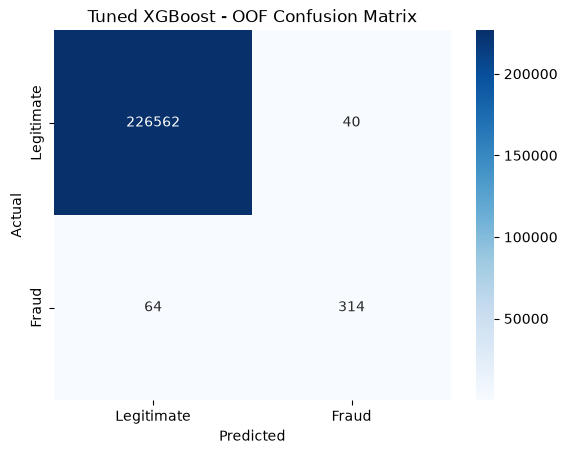

In [16]:
xgb_cm = confusion_matrix(y_train, xgb_oof_pred)

print(xgb_cm)

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned XGBoost - OOF Confusion Matrix")
plt.show()

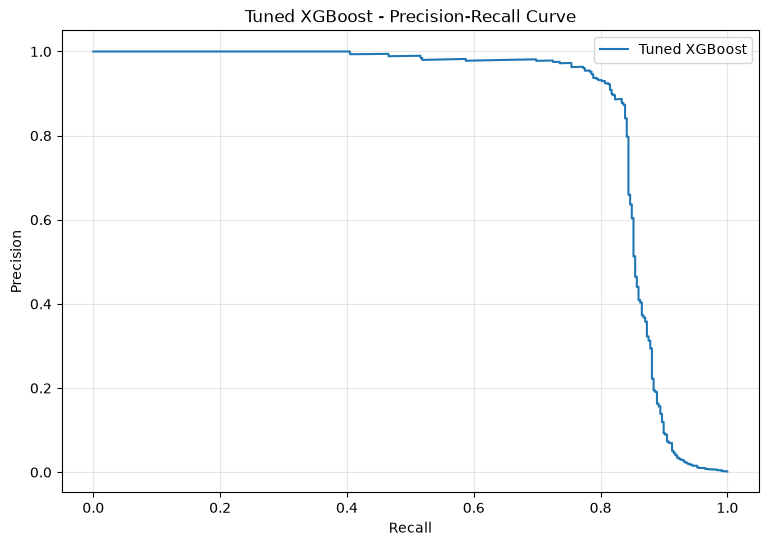

In [17]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_train,
    xgb_oof_proba
)

plt.figure(figsize=(9, 6))

plt.plot(recall, precision, label="Tuned XGBoost")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Tuned XGBoost - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
thresholds_to_test = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds_to_test:
    predictions = (xgb_oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1-Score": f1_score(y_train, predictions),
        "Fraud Alerts": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1-Score,Fraud Alerts
0,0.1,0.7595,0.8439,0.7995,420
1,0.2,0.8391,0.8413,0.8402,379
2,0.3,0.8685,0.8386,0.8533,365
3,0.4,0.8774,0.8333,0.8548,359
4,0.5,0.8870,0.8307,0.8579,354
5,0.6,0.8963,0.8228,0.8579,347
6,0.7,0.9086,0.8148,0.8591,339
7,0.8,0.9222,0.8148,0.8652,334
8,0.9,0.9323,0.8016,0.8620,325


### 1.9 Decision Threshold Analysis

The decision threshold was varied from 0.1 to 0.9 to investigate its effect on fraud detection performance.

The analysis revealed a clear trade-off between precision and recall.

As the decision threshold increased, precision improved from 75.95% at a threshold of 0.1 to 93.23% at 0.9. However, recall decreased from 84.39% to 80.16%.

The number of fraud alerts also decreased from 420 to 325, indicating that higher thresholds made the classifier more selective in identifying potentially fraudulent transactions.

#### Best Performing Threshold

Among the tested thresholds, 0.9 achieved the highest F1-score of 86.20%, with:

- Precision: 93.23%
- Recall: 80.16%
- F1-score: 86.20%
- Fraud alerts: 325

At the default threshold of 0.5, the model achieved an F1-score of 85.79%, precision of 88.70%, and recall of 83.07%.

The threshold of 0.9 therefore provides higher precision and fewer fraud alerts, but at the cost of detecting a smaller proportion of actual fraud cases.

#### Interpretation

The results demonstrate that the decision threshold has a meaningful influence on the operational behaviour of the fraud detection model.

A lower threshold favours fraud detection by capturing more potentially fraudulent transactions, but increases false-positive alerts. A higher threshold reduces unnecessary alerts but increases the number of missed fraud cases.

Although 0.9 achieved the highest F1-score among the tested thresholds, it is retained only as a candidate threshold. The final decision will require consideration of the relative costs of missed fraud and false-positive alerts.

## 3. CatBoost Hyperparameter Tuning

### 3.1 Experiment Objective

The objective of this experiment is to optimize the CatBoost classifier selected during the initial model evaluation phase.

The initial experiment used CatBoost's native class-weighting mechanism (`auto_class_weights="Balanced"`) to address the severe class imbalance in the fraud detection dataset.

CatBoost demonstrated competitive fraud detection performance during the initial evaluation, making it a suitable candidate for further optimization.

### 3.2 Tuning Strategy

We will use RandomizedSearchCV with Stratified K-Fold Cross-Validation to explore different combinations of CatBoost hyperparameters.

The search will focus on parameters that control:

- **Number of iterations:** The number of boosting trees built by the model.
- **Tree complexity:** The depth of individual trees.
- **Learning process:** How much each boosting iteration contributes to the ensemble.
- **Regularization:** How the model controls complexity and reduces overfitting.
- **Randomness:** How random sampling influences model training.

### 3.3 Evaluation Criteria

Average Precision (AP) will remain the primary optimization metric because of the severe class imbalance.

We will also monitor:

- Precision
- Recall
- F1-score
- ROC-AUC

The selected configuration will undergo out-of-fold evaluation, including confusion matrix analysis, precision-recall curve analysis, and decision-threshold investigation.

### 3.4 Experimental Constraints

- Use the existing training dataset.
- Preserve CatBoost's native class-weighting strategy (`auto_class_weights="Balanced"`).
- Use stratified cross-validation to maintain class proportions across folds.
- Keep the test dataset untouched during hyperparameter tuning.
- Compare the tuned CatBoost against its initial baseline configuration.
- Consider computational cost when defining the search space and number of iterations.

### 3.5 Business Context

The proposed fraud detection system is a human-in-the-loop decision-support system.

CatBoost will identify potentially fraudulent transactions and forward them to fraud risk analysts for investigation. The model's predictions will support the analysts' decisions rather than independently determine whether a transaction is fraudulent.

The final model and operating threshold will be selected only after comparing the results of all candidate models.

In [23]:
catboost_model = CatBoostClassifier(
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=0,
    thread_count=1
)

In [24]:
catboost_pipeline = build_pipeline(
    model=catboost_model,
    strategy="Class Weighting"
)

catboost_pipeline

,steps,"[('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False


In [25]:
from scipy.stats import randint, loguniform, uniform

catboost_param_dist = {
    "classifier__iterations": randint(200, 601),
    "classifier__depth": randint(4, 9),
    "classifier__learning_rate": loguniform(0.01, 0.2),
    "classifier__l2_leaf_reg": loguniform(1, 10),
    "classifier__random_strength": uniform(0, 2),
    "classifier__border_count": [32, 64, 128]
}

In [26]:
catboost_search = RandomizedSearchCV(
    estimator=catboost_pipeline,
    param_distributions=catboost_param_dist,
    n_iter=10,
    scoring=scoring,
    refit="average_precision",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    n_jobs=1,
    verbose=2,
    random_state=RANDOM_STATE,
    return_train_score=False
)

start_time = time.time()

catboost_search.fit(X_train, y_train)

catboost_tuning_time = time.time() - start_time

print(f"Tuning time: {catboost_tuning_time / 60:.2f} minutes")
print(f"Best Average Precision: {catboost_search.best_score_:.4f}")

print("\nBest Parameters:")
for parameter, value in catboost_search.best_params_.items():
    print(f"{parameter}: {value}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END classifier__border_count=128, classifier__depth=7, classifier__iterations=548, classifier__l2_leaf_reg=1.5255793090045733, classifier__learning_rate=0.10337163339642635, classifier__random_strength=1.193700315892974; total time=  38.4s
[CV] END classifier__border_count=128, classifier__depth=7, classifier__iterations=548, classifier__l2_leaf_reg=1.5255793090045733, classifier__learning_rate=0.10337163339642635, classifier__random_strength=1.193700315892974; total time=  42.0s
[CV] END classifier__border_count=128, classifier__depth=7, classifier__iterations=548, classifier__l2_leaf_reg=1.5255793090045733, classifier__learning_rate=0.10337163339642635, classifier__random_strength=1.193700315892974; total time=  41.3s
[CV] END classifier__border_count=64, classifier__depth=6, classifier__iterations=414, classifier__l2_leaf_reg=1.1430983876313219, classifier__learning_rate=0.13394334706750485, classifier__random_strengt

In [27]:
best_index = catboost_search.best_index_

print("Best CV Results:")

for metric in scoring:
    mean_score = catboost_search.cv_results_[f"mean_test_{metric}"][best_index]
    std_score = catboost_search.cv_results_[f"std_test_{metric}"][best_index]

    print(f"{metric}: {mean_score:.4f} ± {std_score:.4f}")

Best CV Results:
precision: 0.8633 ± 0.0418
recall: 0.8228 ± 0.0368
f1: 0.8417 ± 0.0284
average_precision: 0.8403 ± 0.0230
roc_auc: 0.9699 ± 0.0062


In [28]:
catboost_best_pipeline = catboost_search.best_estimator_

catboost_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

catboost_oof_proba = cross_val_predict(
    catboost_best_pipeline,
    X_train,
    y_train,
    cv=catboost_cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

In [29]:
catboost_oof_pred = (
    catboost_oof_proba >= 0.5
).astype(int)

In [30]:
catboost_oof_metrics = {
    "Precision": precision_score(y_train, catboost_oof_pred),
    "Recall": recall_score(y_train, catboost_oof_pred),
    "F1-Score": f1_score(y_train, catboost_oof_pred),
    "Average Precision": average_precision_score(
        y_train, catboost_oof_proba
    ),
    "ROC-AUC": roc_auc_score(y_train, catboost_oof_proba)
}

pd.DataFrame(
    catboost_oof_metrics.items(),
    columns=["Metric", "Score"]
)

,Metric,Score
0,Precision,0.861496
1,Recall,0.822751
2,F1-Score,0.841678
3,Average Precision,0.840734
4,ROC-AUC,0.970174


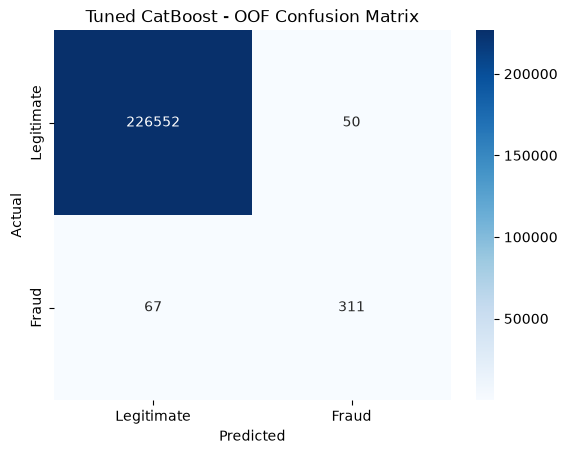

In [31]:
catboost_cm = confusion_matrix(
    y_train,
    catboost_oof_pred
)

sns.heatmap(
    catboost_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned CatBoost - OOF Confusion Matrix")
plt.show()

### 3.10 CatBoost Evaluation and Comparison with Initial Models

#### Out-of-Fold Evaluation Results

The tuned CatBoost model achieved the following OOF performance at the default decision threshold of 0.5:

| Metric | Score |
|---|---:|
| Precision | 86.15% |
| Recall | 82.28% |
| F1-score | 84.17% |
| Average Precision | 84.07% |
| ROC-AUC | 97.02% |

Its confusion matrix showed:

- True Positives: 311
- False Positives: 50
- False Negatives: 67
- True Negatives: 226,552

The model correctly identified 311 fraudulent transactions while generating 50 false-positive alerts.

#### Comparison with Initial CatBoost

Compared with the initial CatBoost configuration, hyperparameter tuning increased precision from 81.75% to 86.15% and F1-score from 82.92% to 84.17%.

Average Precision also improved slightly from 83.78% to 84.07%.

However, recall decreased from 84.13% to 82.28%, while ROC-AUC decreased from 97.57% to 97.02%.

This indicates that the tuned configuration became more selective, reducing false-positive alerts but missing a greater proportion of fraudulent transactions.

#### Comparison with XGBoost

The four evaluated configurations demonstrated different performance characteristics.

Initial XGBoost achieved the highest precision (92.54%) and F1-score (86.96%). Tuned XGBoost achieved the highest Average Precision (85.31%) and ROC-AUC (98.17%).

Initial CatBoost achieved the highest recall (84.13%) and detected 318 fraudulent transactions, although it generated 71 false-positive alerts.

Tuned CatBoost improved precision relative to its initial configuration but did not outperform the XGBoost configurations on the principal ranking metrics.

#### Preliminary Conclusion

Hyperparameter tuning produced a modest improvement in CatBoost's precision and F1-score, but did not consistently improve all evaluation metrics.

The initial and tuned CatBoost configurations will both remain available for the final model comparison.

No final model or decision threshold is selected at this stage. Further evaluation will consider precision, recall, Average Precision, ROC-AUC, false-positive alerts, and the operational requirements of the proposed human-in-the-loop fraud detection system.

In [33]:
catboost_tuned_threshold_results = []

for threshold in thresholds_to_test:
    predictions = (catboost_oof_proba >= threshold).astype(int)

    catboost_tuned_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1-Score": f1_score(y_train, predictions),
        "Fraud Alerts": predictions.sum()
    })

catboost_tuned_threshold_df = pd.DataFrame(
    catboost_tuned_threshold_results
)

catboost_tuned_threshold_df.round(4)

,Threshold,Precision,Recall,F1-Score,Fraud Alerts
0,0.1,0.6157,0.8519,0.7148,523
1,0.2,0.7329,0.8492,0.7868,438
2,0.3,0.7950,0.8413,0.8175,400
3,0.4,0.8324,0.8280,0.8302,376
4,0.5,0.8615,0.8228,0.8417,361
5,0.6,0.8754,0.8175,0.8454,353
6,0.7,0.8870,0.8095,0.8465,345
7,0.8,0.9045,0.8016,0.8499,335
8,0.9,0.9202,0.7937,0.8523,326


### 3.10 CatBoost Threshold Analysis and Comparison

The decision threshold was varied from 0.1 to 0.9 to investigate the effect of threshold selection on the initial and tuned CatBoost configurations.

#### Initial vs. Tuned CatBoost

The tuned CatBoost configuration achieved higher precision across all tested thresholds. However, the initial configuration consistently achieved higher recall.

At a threshold of 0.3, initial CatBoost achieved 72.83% precision and 84.39% recall, while tuned CatBoost achieved 79.50% precision and 84.13% recall.

At the default threshold of 0.5, initial CatBoost achieved 81.75% precision, 84.13% recall, and an F1-score of 82.92%. Tuned CatBoost achieved 86.15% precision, 82.28% recall, and an F1-score of 84.17%.

The tuned model therefore improved precision and F1-score while reducing recall.

#### Interpretation

The results suggest that hyperparameter tuning made CatBoost more selective in identifying potentially fraudulent transactions.

The reduction in false-positive alerts comes with a corresponding reduction in fraud detection recall. This trade-off is relevant to the proposed human-in-the-loop fraud detection architecture, where analysts investigate flagged transactions.

Neither configuration is selected as the final CatBoost model at this stage. Both will remain available for the consolidated comparison against XGBoost and the other candidate models.

In [34]:
xgb_comparison = pd.DataFrame([
    {
        "Model": "Initial XGBoost",
        "Threshold": 0.3,
        "Precision": 0.8994,
        "Recall": 0.8280,
        "F1-Score": 0.8623,
        "Fraud Alerts": 348
    },
    {
        "Model": "Initial XGBoost",
        "Threshold": 0.5,
        "Precision": 0.9254,
        "Recall": 0.8201,
        "F1-Score": 0.8696,
        "Fraud Alerts": 335
    },
    {
        "Model": "Initial XGBoost",
        "Threshold": 0.9,
        "Precision": 0.9444,
        "Recall": 0.8095,
        "F1-Score": 0.8718,
        "Fraud Alerts": 324
    },
    {
        "Model": "Tuned XGBoost",
        "Threshold": 0.3,
        "Precision": 0.8685,
        "Recall": 0.8386,
        "F1-Score": 0.8533,
        "Fraud Alerts": 365
    },
    {
        "Model": "Tuned XGBoost",
        "Threshold": 0.5,
        "Precision": 0.8870,
        "Recall": 0.8307,
        "F1-Score": 0.8579,
        "Fraud Alerts": 354
    },
    {
        "Model": "Tuned XGBoost",
        "Threshold": 0.9,
        "Precision": 0.9323,
        "Recall": 0.8016,
        "F1-Score": 0.8620,
        "Fraud Alerts": 325
    }
])

xgb_comparison

,Model,Threshold,Precision,Recall,F1-Score,Fraud Alerts
0,Initial XGBoost,0.3,0.8994,0.8280,0.8623,348
1,Initial XGBoost,0.5,0.9254,0.8201,0.8696,335
2,Initial XGBoost,0.9,0.9444,0.8095,0.8718,324
3,Tuned XGBoost,0.3,0.8685,0.8386,0.8533,365
4,Tuned XGBoost,0.5,0.8870,0.8307,0.8579,354
5,Tuned XGBoost,0.9,0.9323,0.8016,0.8620,325


### 4.1 Comparison of Initial and Tuned XGBoost

The initial and tuned XGBoost configurations were compared at decision thresholds of 0.3, 0.5, and 0.9 to examine their different operating behaviours.

#### Key Observations

At threshold 0.3:

- Initial XGBoost achieved 89.94% precision, 82.80% recall, and an F1-score of 86.23%.
- Tuned XGBoost achieved 86.85% precision, 83.86% recall, and an F1-score of 85.33%.

The tuned configuration detected a slightly larger proportion of fraudulent transactions but generated more fraud alerts.

At threshold 0.5, initial XGBoost achieved a higher precision and F1-score, while tuned XGBoost maintained slightly higher recall.

At threshold 0.9, both configurations demonstrated higher precision but lower recall, reflecting a more selective fraud detection behaviour.

#### Preliminary Interpretation

The initial XGBoost configuration appears particularly promising for the intended fraud detection system because it offers a favourable balance between precision and recall at threshold 0.3.

Although hyperparameter tuning improved the Average Precision and ROC-AUC of XGBoost, these improvements did not translate into better performance across all operational metrics.

The tuned configuration remains a candidate because of its slightly higher recall and improved ranking metrics.

#### Provisional Decision

Both initial and tuned XGBoost configurations will be retained for final evaluation.

The threshold analysis suggests that 0.3 is a promising operating threshold, particularly for the initial configuration, given the system's human-in-the-loop design.

However, neither the final model nor its operating threshold has been selected. Both configurations must undergo evaluation on the untouched test dataset before a final decision is made.

In [35]:
initial_xgb_model = XGBClassifier()

initial_xgb_pipeline = build_pipeline(
    model=initial_xgb_model,
    strategy="Class Weighting"
)

In [36]:
tuned_xgb_pipeline = xgb_search.best_estimator_

In [37]:
start_time = time.time()

initial_xgb_pipeline.fit(X_train, y_train)

initial_xgb_fit_time = time.time() - start_time

print(f"Initial XGBoost fit time: {initial_xgb_fit_time:.2f} seconds")

Initial XGBoost fit time: 3.42 seconds


In [38]:
initial_xgb_test_proba = initial_xgb_pipeline.predict_proba(X_test)[:, 1]

tuned_xgb_test_proba = tuned_xgb_pipeline.predict_proba(X_test)[:, 1]

In [39]:
THRESHOLD = 0.3

initial_xgb_test_pred = (
    initial_xgb_test_proba >= THRESHOLD
).astype(int)

tuned_xgb_test_pred = (
    tuned_xgb_test_proba >= THRESHOLD
).astype(int)

In [40]:
def evaluate_model(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Average Precision": average_precision_score(y_true, y_proba),
        "ROC-AUC": roc_auc_score(y_true, y_proba)
    }


test_results = pd.DataFrame([
    evaluate_model(
        y_test, initial_xgb_test_pred,
        initial_xgb_test_proba, "Initial XGBoost"
    ),
    evaluate_model(
        y_test, tuned_xgb_test_pred,
        tuned_xgb_test_proba, "Tuned XGBoost"
    )
])

test_results

,Model,Accuracy,Precision,Recall,F1,Average Precision,ROC-AUC
0,Initial XGBoost,0.999471,0.901235,0.768421,0.829545,0.823624,0.979006
1,Tuned XGBoost,0.999542,0.905882,0.810526,0.855556,0.818054,0.979111


In [41]:
initial_xgb_cm = confusion_matrix(
    y_test, initial_xgb_test_pred
)

tuned_xgb_cm = confusion_matrix(
    y_test, tuned_xgb_test_pred
)

print("Initial XGBoost:")
print(initial_xgb_cm)

print("\nTuned XGBoost:")
print(tuned_xgb_cm)

Initial XGBoost:
[[56643     8]
 [   22    73]]

Tuned XGBoost:
[[56643     8]
 [   18    77]]


In [42]:
import joblib
from pathlib import Path

# Final model configuration
FINAL_THRESHOLD = 0.3

final_model = tuned_xgb_pipeline

final_model_params = xgb_search.best_params_

# Package everything required for inference
final_model_artifact = {
    "model": final_model,
    "threshold": FINAL_THRESHOLD,
    "best_params": final_model_params,
    "model_name": "Tuned XGBoost",
    "imbalance_strategy": "Class Weighting",
    "random_state": RANDOM_STATE
}

# Create model directory
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save artifact
model_path = MODEL_DIR / "fraud_detection_xgboost.joblib"

joblib.dump(final_model_artifact, model_path)

print(f"Final model saved to: {model_path}")

Final model saved to: ../models/fraud_detection_xgboost.joblib



# Experiment 4: XGBoost Hyperparameter Tuning and Final Model Evaluation

## 1. Experiment Objective

The objective of this experiment was to improve the performance of the initial XGBoost model through hyperparameter tuning and determine whether the tuned model provides better fraud detection performance.

The initial XGBoost model, using the class-weighting strategy, was selected as one of the strongest candidates from the previous experiment.

Rather than repeating the initial model comparison, this experiment focused on tuning XGBoost and comparing its performance against the initial baseline.

The evaluation was conducted using the training and test datasets prepared in Notebook 2. The test dataset was kept separate from the hyperparameter tuning and cross-validation process.

## 2. Hyperparameter Tuning

RandomizedSearchCV was used to explore different combinations of XGBoost hyperparameters.

The search was conducted using:

- **Search method:** RandomizedSearchCV
- **Number of iterations:** 20
- **Cross-validation:** 5-fold StratifiedKFold
- **Primary optimization metric:** Average Precision
- **Refit strategy:** Average Precision
- **Parallel processing:** 1 job

Average Precision was selected as the primary optimization metric because the dataset is highly imbalanced, with fraudulent transactions representing only a small proportion of the observations.

### Best Hyperparameters

The hyperparameter search identified the following configuration:

| Hyperparameter | Selected Value |
|---|---:|
| n_estimators | 443 |
| max_depth | 7 |
| learning_rate | 0.0703 |
| subsample | 0.7545 |
| colsample_bytree | 0.8001 |
| min_child_weight | 2 |
| gamma | 0.7143 |
| reg_alpha | 1.4528 |
| reg_lambda | 0.2659 |

The tuned model retained the class-weighting strategy used in the initial experiment.

## 3. Cross-Validation Results

The best configuration achieved the following mean cross-validation performance:

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Precision | 0.8897 | 0.0442 |
| Recall | 0.8307 | 0.0421 |
| F1-score | 0.8580 | 0.0288 |
| Average Precision | 0.8545 | 0.0281 |
| ROC-AUC | 0.9819 | 0.0082 |

The tuned model demonstrated strong cross-validation performance, with an Average Precision score of approximately 0.8545.

These results indicate that the model maintained good fraud detection performance across the cross-validation folds.

## 4. Decision Threshold Selection

The default classification threshold of 0.5 was not automatically retained.

Instead, different probability thresholds were examined using out-of-fold predictions generated from the training dataset.

The threshold determines the minimum predicted fraud probability required for a transaction to be flagged for investigation.

A threshold of **0.3** was selected as the operating threshold for the final evaluation.

At this threshold, the tuned model achieved the following out-of-fold results:

| Metric | OOF Result |
|---|---:|
| Precision | 86.85% |
| Recall | 83.86% |
| F1-score | 85.33% |
| Average Precision | 84.07% |
| ROC-AUC | 97.02% |

The threshold was selected to balance fraud detection coverage and the number of transactions requiring analyst investigation.

The selected threshold was fixed before evaluating the model on the test dataset.

## 5. Independent Test Evaluation

After hyperparameter tuning and threshold selection, the tuned XGBoost model was evaluated on the untouched test dataset.

The same threshold of 0.3 was applied during evaluation.

### Test Performance

| Metric | Initial XGBoost | Tuned XGBoost |
|---|---:|---:|
| Accuracy | 99.9471% | 99.9542% |
| Precision | 90.12% | 90.59% |
| Recall | 76.84% | 81.05% |
| F1-score | 82.95% | 85.56% |
| Average Precision | 82.36% | 81.81% |
| ROC-AUC | 97.90% | 97.91% |

The tuned model achieved higher precision, recall, F1-score, and ROC-AUC than the initial model on the independent test dataset.

However, the initial model recorded a slightly higher Average Precision score.

This indicates that although the tuned model performed better at the selected operating threshold, the initial model had a marginally better overall precision-recall ranking score.

### Confusion Matrix: Initial XGBoost

| Actual / Predicted | Legitimate (0) | Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 56,643 | 8 |
| Fraud (1) | 22 | 73 |

### Confusion Matrix: Tuned XGBoost

| Actual / Predicted | Legitimate (0) | Fraud (1) |
|---|---:|---:|
| Legitimate (0) | 56,643 | 8 |
| Fraud (1) | 18 | 77 |

### Operational Interpretation

At the selected threshold of 0.3:

- The initial model detected 73 fraudulent transactions and missed 22.
- The tuned model detected 77 fraudulent transactions and missed 18.
- Both models generated 8 false-positive alerts.
- The tuned model identified 4 additional fraudulent transactions without increasing the number of false-positive alerts.

For the intended human-in-the-loop fraud detection system, this is an important improvement.

The model flags potentially fraudulent transactions for further investigation by a fraud risk analyst. It does not independently establish fraud or automatically block transactions.

The reduction in missed fraud cases improves detection coverage, while maintaining the same false-positive workload in this test evaluation.

## 6. Final Model Selection

The tuned XGBoost model was selected as the final model for the fraud detection system.

The selection was based primarily on its performance at the chosen operating threshold of 0.3.

Compared with the initial XGBoost model, the tuned model achieved:

- Higher precision: 90.59% compared with 90.12%.
- Higher recall: 81.05% compared with 76.84%.
- Higher F1-score: 85.56% compared with 82.95%.
- Four additional correctly detected fraudulent transactions.
- The same number of false-positive alerts.

Although the initial model achieved a slightly higher Average Precision score, the tuned model provided a more favorable operational outcome at the selected threshold.

The test dataset contained 95 fraudulent transactions. Therefore, the evaluation results should be interpreted with consideration of the limited number of positive cases and the uncertainty associated with the reported metrics.

### Final Model Configuration

| Component | Selected Configuration |
|---|---|
| Model | Tuned XGBoost |
| Imbalance handling | Class Weighting |
| Hyperparameter optimization | RandomizedSearchCV |
| Optimization metric | Average Precision |
| Decision threshold | 0.30 |
| Test precision | 90.59% |
| Test recall | 81.05% |
| Test F1-score | 85.56% |
| Test Average Precision | 81.81% |
| Test ROC-AUC | 97.91% |

The trained model, selected threshold, and best hyperparameters were saved together as a serialized model artifact for subsequent packaging and deployment.

## 7. Experiment Conclusion

Hyperparameter tuning improved the operational performance of the initial XGBoost model at the selected classification threshold.

The tuned model demonstrated better fraud detection coverage while maintaining the same false-positive count on the independent test dataset.

The final model will serve as the prediction engine for the fraud detection system. Its output will represent a fraud risk prediction that supports human investigation rather than an autonomous fraud verdict.

The selected model and its decision threshold will be preserved during subsequent packaging and deployment activities.

**Final selected model: Tuned XGBoost with Class Weighting and a decision threshold of 0.30.**
